# COMP-548DL Homework 1 - Exercise 2


Setup a number of VMs or Containers of different size (i.e., 1, 2, 4, 8 GBs of RAM), run a data 
intensive load (e.g. external sorting) and measure its effects on the performance of the 
VM/Container using suitable measures elaborated through the lecture notes. 

In [1]:
# Requirements for this notebook (the sorting itself runs inside Docker):
# !pip install docker pandas matplotlib

In [1]:
# import necessary libraries

import docker
import pandas as pd
import json
from pathlib import Path
import matplotlib.pyplot as plt

In [ ]:
# check if Docker is running and get its version, number of CPUs, RAM, and cgroup version

client = docker.from_env()
info = client.info()

print("Docker version:", info["ServerVersion"])
print("CPUs available to Docker:", info["NCPU"])
print("RAM available to Docker:", round(info["MemTotal"] / 2**30, 1), "GB")
print("cgroup version:", info["CgroupVersion"])

Docker version: 29.8.2
CPUs available to Docker: 8
RAM available to Docker: 11.7 GB
cgroup version: 2


In [4]:
# code taken from Lecture 2
# to generate datasets of sizes 10^1, 10^2, ..., 10^8

import os, sys, csv, time, random

def data_generator(datapoints):

    dataset = []
    for i in range(datapoints):
        userid = 'user' + str(i)
        score = random.randint(1, 100000)
        dataset.append((userid, score))
    random.shuffle(dataset)
    return dataset

def generate_datasets(exp):
    
    for i in range(exp):
        dataset_list = data_generator(10**(i+1))
        print('finished d')
        fname = 'dataset_exp_' + str(i+1) + '.csv'
        with open(fname, 'w', newline='') as unsorted_f:
            writer = csv.writer(unsorted_f)
            for item in dataset_list:
                writer.writerow(item)

# added this code to generate a large dataset of size 10^8, written row by row to avoid memory issues

def generate_large(exp):
    
    # data_generator(10**8) would need ~15 GB of RAM, so the rows are written one at a time
    
    with open('dataset_exp_' + str(exp) + '.csv', 'w', newline='') as f:
        csv.writer(f).writerows(('user' + str(i), random.randint(1, 100000)) for i in range(10**exp))
    print('finished 10^' + str(exp))

generate_datasets(7)   # 10^1 ... 10^7 with the lecture code
generate_large(8)      # 10^8 written row by row

finished d
finished d
finished d
finished d
finished d
finished d
finished d
finished 10^8


In [ ]:
# create a Docker client to run containers

client = docker.from_env()

RAM_SIZES = [1, 2, 4, 8]
results = []
current_folder = str(Path.cwd())

# run the external sorting experiment with different RAM sizes 1,2,4 and 8 GB, and collect the results

for ram in RAM_SIZES:

    print(f"\nRunning with {ram} GB RAM")

    container = client.containers.run(

        image="python:3.11",
        
        # run the external sorting script inside the container, installing the required packages first
        command=["sh", "-c", "pip install -q toolz contextlib2 2>/dev/null && python external_sorting.py 8"],

        volumes={
            current_folder: {
                "bind": "/work",
                "mode": "rw"
            }
        },
        working_dir="/work",
        mem_limit=f"{ram}g",
        memswap_limit=f"{ram}g",
        detach=True
    )

    status = container.wait()["StatusCode"]
    output = container.logs().decode().strip()
    container.remove()

    # check if the container exited with a non-zero status code (indicating an error)

    if status != 0:
        print(f"{ram} GB run failed (exit code {status}, 137 = out of memory)")
        continue

    # parse the output of the container to extract the timings and compute latency, response time, 
    # throughput, and CPU utilization
    
    stats = json.loads(
        output.splitlines()[-1]
    )

    wait = 0

    # compute latency, response time, throughput and CPU utilization for each dataset size

    for exp, processing_time, cpu_time in stats["timings"]:

        latency = wait
        response_time = latency + processing_time
        throughput = (10 ** exp) / processing_time
        cpu_util = 100 * cpu_time / processing_time

        results.append({

            "RAM_GB": ram,
            "Dataset": f"10^{exp}",
            "Latency_s": round(latency, 2),
            "Processing_Time_s": round(processing_time, 2),
            "Response_Time_s": round(response_time, 2),
            "Throughput": round(throughput, 2),
            "CPU_Time_s": round(cpu_time, 2),
            "CPU_Util_%": round(cpu_util, 1)
        })

        wait += processing_time

# create a DataFrame from the results and save it to a CSV file

df = pd.DataFrame(results)

# save the results to a CSV file
df.to_csv(
    "results.csv",
    index=False
)

print("\nResults saved to results.csv")


Running with 1 GB RAM

Running with 2 GB RAM

Running with 4 GB RAM

Running with 8 GB RAM

Results saved to results.csv


In [2]:
# all metrics per container for the largest dataset (10^8)

df = pd.read_csv("results.csv")

cols = {"Response_Time_s": "Response time (s)", "Processing_Time_s": "Processing time (s)",
        "Throughput": "Throughput (records/s)", "Latency_s": "Latency (s)",
        "CPU_Time_s": "CPU time (s)", "CPU_Util_%": "CPU use (%)"}

table = df[df["Dataset"] == "10^8"].set_index("RAM_GB")[list(cols)].rename(columns=cols).round(1)
table.index = table.index.astype(str) + " GB"
table.index.name = "Container"
table


,Response time (s),Processing time (s),Throughput (records/s),Latency (s),CPU time (s),CPU use (%)
Container,,,,,,
1 GB,889.2,820.1,121939.6,69.1,467.1,57.0
2 GB,854.9,781.6,127944.0,73.3,440.8,56.4
4 GB,844.5,768.7,130083.5,75.8,435.1,56.6
8 GB,847.3,773.8,129230.3,73.5,434.1,56.1


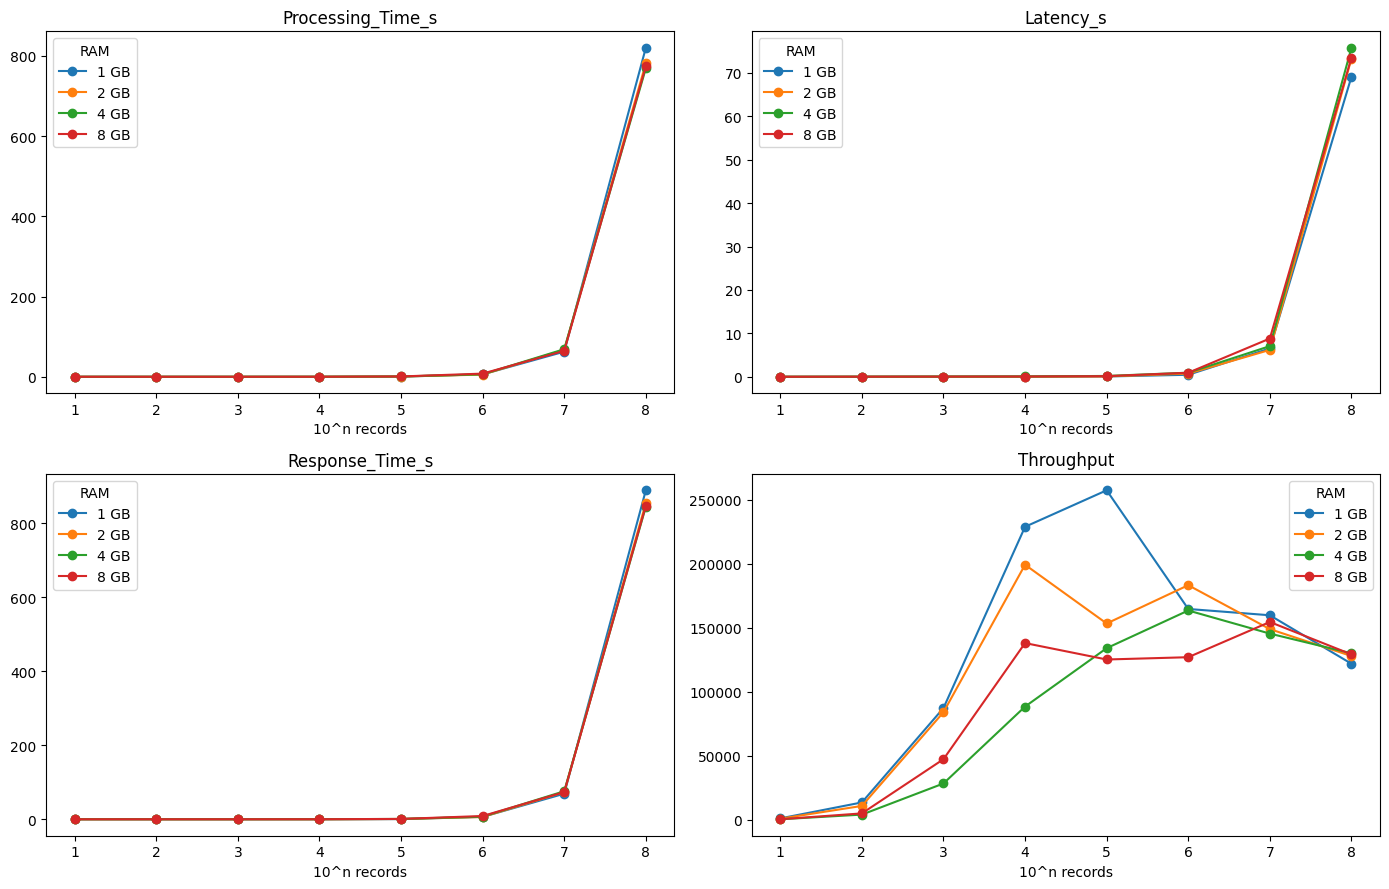

In [4]:
# plot the performance measures and CPU utilization for different RAM sizes

df = pd.read_csv("results.csv")
df["exp"] = df["Dataset"].str[3:].astype(int)
p = lambda col: (df.pivot(index="exp", columns="RAM_GB", values=col)
                   .rename(columns=lambda r: f"{r} GB")
                   .rename_axis(columns="RAM"))

# performance measures

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.flat, ["Processing_Time_s", "Latency_s", "Response_Time_s", "Throughput"]):
    p(col).plot(ax=ax, marker="o", title=col, xlabel="10^n records")
plt.tight_layout(); plt.show()
